<a href="https://colab.research.google.com/github/deva123932/CSA-4703-DL/blob/main/exp_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 5: Bias–Variance, Overfitting and Underfitting Analysis

This notebook demonstrates underfitting, good fit, and overfitting using polynomial regression of degrees 1, 3, 9, and 15, and estimates bias and variance via resampling.

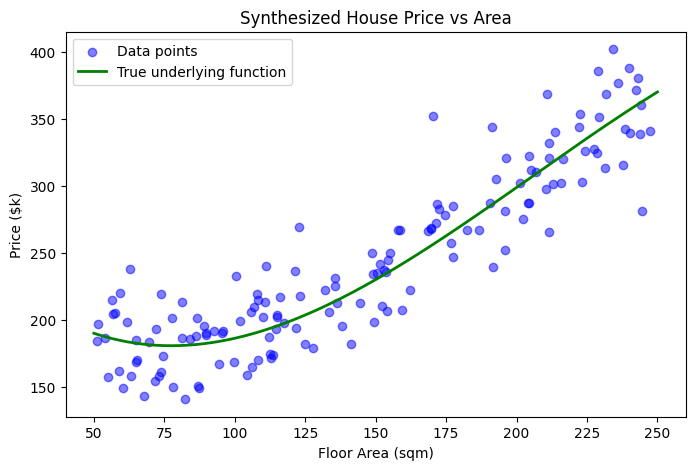

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.utils import resample

# Set seed for reproducibility
np.random.seed(42)

# 1. Generate 150 synthetic noisy samples with a non-linear relationship
X = np.sort(np.random.uniform(50, 250, 150))[:, np.newaxis] # Floor area in sq meters
true_fun = lambda x: 50 + 1.2 * x + 0.005 * (x - 150)**2 - 0.00003 * (x - 150)**3
y = true_fun(X.ravel()) + np.random.normal(0, 25, 150) # Price with added noise

# Split into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.3, random_state=42)

# Plot the generated data
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='blue', alpha=0.5, label='Data points')
x_plot = np.linspace(50, 250, 500)[:, np.newaxis]
plt.plot(x_plot, true_fun(x_plot), color='green', label='True underlying function', linewidth=2)
plt.xlabel('Floor Area (sqm)')
plt.ylabel('Price ($k)')
plt.title('Synthesized House Price vs Area')
plt.legend()
plt.show()

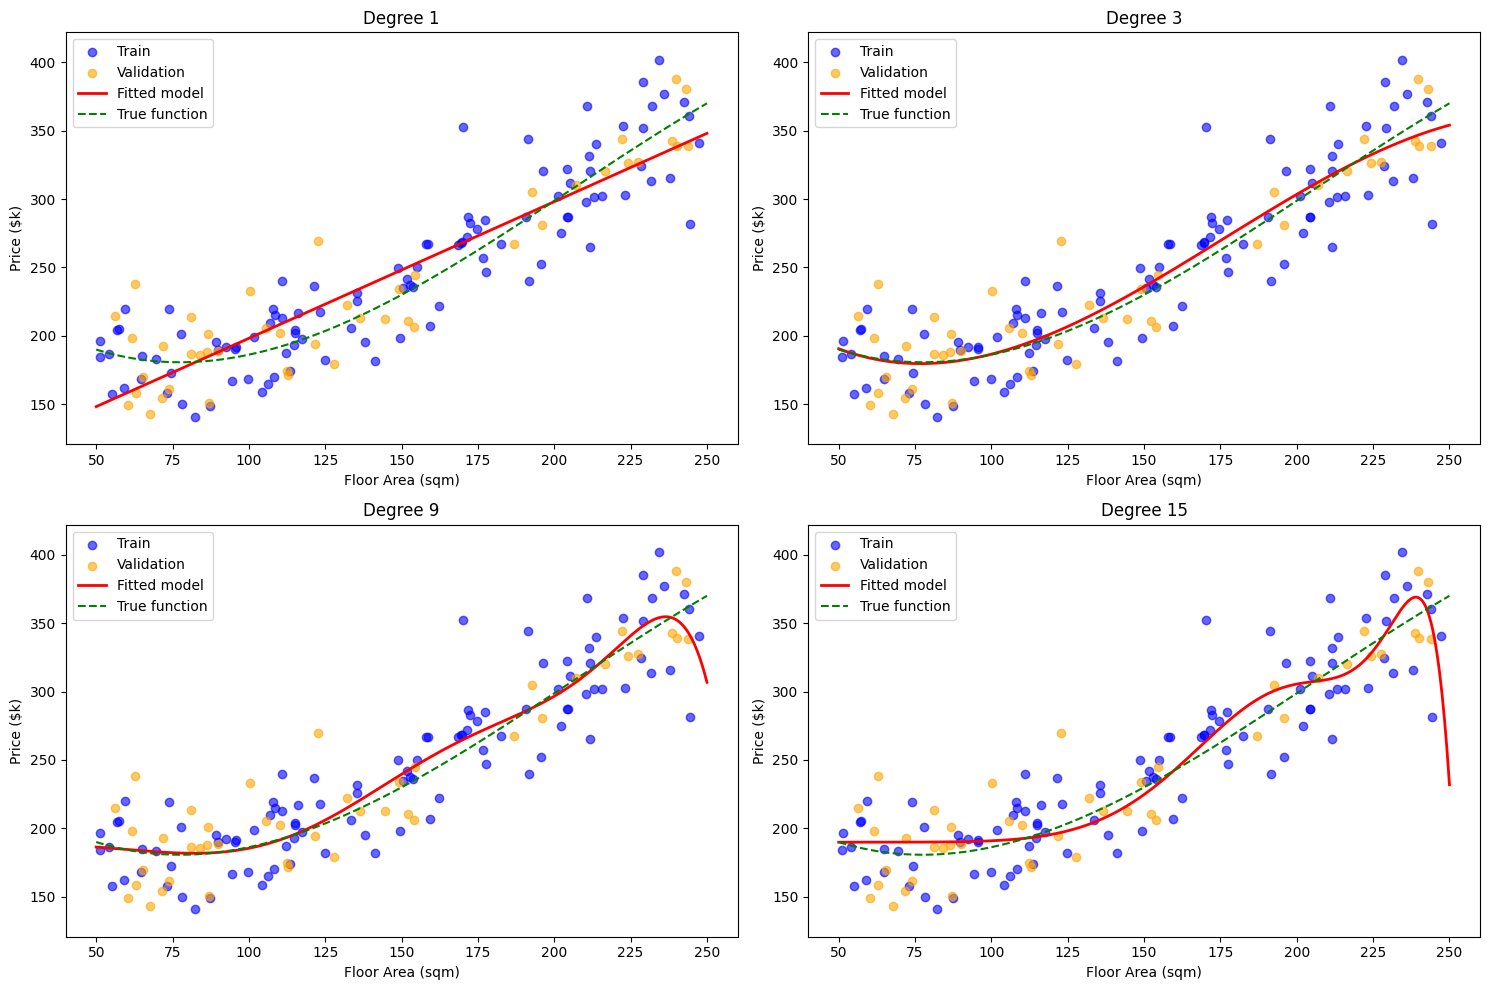

In [2]:
# 2. Fit and plot polynomial regression of degree 1, 3, 9, and 15
degrees = [1, 3, 9, 15]
plt.figure(figsize=(15, 10))

for i, degree in enumerate(degrees):
    ax = plt.subplot(2, 2, i + 1)

    # Pipeline for polynomial regression
    model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
    model.fit(X_train, y_train)

    # Predict over grid
    y_plot = model.predict(x_plot)

    # Plot train and validation points along with the fitted curve
    ax.scatter(X_train, y_train, color='blue', alpha=0.6, label='Train')
    ax.scatter(X_val, y_val, color='orange', alpha=0.6, label='Validation')
    ax.plot(x_plot, y_plot, color='red', label='Fitted model', linewidth=2)
    ax.plot(x_plot, true_fun(x_plot), color='green', linestyle='--', label='True function')

    ax.set_ylim(min(y) - 20, max(y) + 20)
    ax.set_xlabel('Floor Area (sqm)')
    ax.set_ylabel('Price ($k)')
    ax.set_title(f'Degree {degree}')
    ax.legend()

plt.tight_layout()
plt.show()

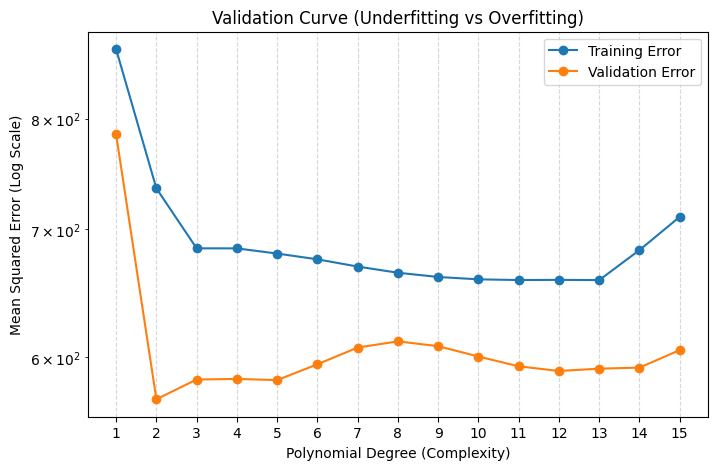

In [3]:
# 3. Plot training and validation error against model complexity (degrees 1 to 15)
all_degrees = np.arange(1, 16)
train_errors = []
val_errors = []

for d in all_degrees:
    model = make_pipeline(PolynomialFeatures(d), LinearRegression())
    model.fit(X_train, y_train)

    train_errors.append(mean_squared_error(y_train, model.predict(X_train)))
    val_errors.append(mean_squared_error(y_val, model.predict(X_val)))

plt.figure(figsize=(8, 5))
plt.plot(all_degrees, train_errors, label='Training Error', marker='o')
plt.plot(all_degrees, val_errors, label='Validation Error', marker='o')
plt.yscale('log')
plt.xlabel('Polynomial Degree (Complexity)')
plt.ylabel('Mean Squared Error (Log Scale)')
plt.title('Validation Curve (Underfitting vs Overfitting)')
plt.xticks(all_degrees)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [4]:
# 4. Estimate bias^2 and variance through repeated resampling (bootstrapping)
n_bootstraps = 100
x_test = np.linspace(50, 250, 100)[:, np.newaxis]
y_test_true = true_fun(x_test.ravel())

biases_sq = []
variances = []

for d in degrees:
    predictions = np.zeros((n_bootstraps, len(x_test)))

    for b in range(n_bootstraps):
        # Resample the training set
        X_res, y_res = resample(X_train, y_train, random_state=b)
        model = make_pipeline(PolynomialFeatures(d), LinearRegression())
        model.fit(X_res, y_res)
        predictions[b, :] = model.predict(x_test)

    # Mean prediction for each test point across all bootstrap runs
    mean_pred = np.mean(predictions, axis=0)

    # Bias^2 = mean of (mean prediction - true value)^2
    bias_sq = np.mean((mean_pred - y_test_true) ** 2)
    # Variance = mean of predictions variance across bootstrap runs
    variance = np.mean(np.var(predictions, axis=0))

    biases_sq.append(bias_sq)
    variances.append(variance)
    print(f"Degree {d:2d} | Bias^2: {bias_sq:8.2f} | Variance: {variance:8.2f} | Total: {(bias_sq + variance):8.2f}")

Degree  1 | Bias^2:   256.21 | Variance:    19.29 | Total:   275.49
Degree  3 | Bias^2:    29.39 | Variance:    33.07 | Total:    62.47
Degree  9 | Bias^2:    92.90 | Variance:    78.95 | Total:   171.85
Degree 15 | Bias^2:   489.29 | Variance:   184.90 | Total:   674.19


### 5. Best Degree Selection and Justification
- **Degree 1 (Underfitting):** High bias, low variance. The model is too restrictive to capture the curve.
- **Degree 3 (Good Fit):** Low bias and low variance. This degree balances complexity and performance, generalizing well to unseen data.
- **Degree 9 & 15 (Overfitting):** Low bias on training data but extremely high variance. The coefficients grow huge, causing wild oscillations between points.

**Conclusion:** Degree 3 provides the optimal trade-off.